# 05 - XGBoost Hyperparameter Tuning & Threshold Optimization

## Overview
This notebook tunes the **XGBoost Churn Classifier** using 5-fold Stratified Cross-Validation (`RandomizedSearchCV`) **on the training set only**.

Following tuning, we sweep decision thresholds (0.1 to 0.9) to optimize the business decision threshold under asymmetric financial costs: **$500 per missed churner (False Negative)** vs **$50 per unnecessary retention offer (False Positive)**. The final tuned model is persisted to `models/xgb_churn.pkl`.

In [1]:
import sys
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

sys.path.insert(0, os.path.abspath('..'))
from src.preprocessing import prepare_data

from xgboost import XGBClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

sns.set_theme(style="whitegrid")
print("Libraries successfully imported.")

Libraries successfully imported.


In [2]:
# Load raw data and preprocessed splits
data_path = os.path.join("..", "data", "Telco-Customer-Churn.csv") if os.path.exists(os.path.join("..", "data", "Telco-Customer-Churn.csv")) else os.path.join("data", "Telco-Customer-Churn.csv")
df_raw = pd.read_csv(data_path)

X_train, X_test, y_train, y_test, X_train_scaled, X_test_scaled, imputer, scaler = prepare_data(df_raw)

# Calculate scale_pos_weight on TRAIN set
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
print(f"X_train shape: {X_train.shape}, X_test shape: {X_test.shape}")
print(f"scale_pos_weight: {scale_pos_weight:.4f}")

X_train shape: (5634, 30), X_test shape: (1409, 30)
scale_pos_weight: 2.7686


In [3]:
# Define hyperparameter search space
param_distributions = {
    'max_depth': [3, 4, 5, 6],
    'learning_rate': [0.01, 0.03, 0.05, 0.1, 0.15, 0.2],
    'n_estimators': [200, 300, 400, 500, 600],
    'subsample': [0.7, 0.8, 0.9, 1.0],
    'colsample_bytree': [0.7, 0.8, 0.9, 1.0]
}

base_xgb = XGBClassifier(
    scale_pos_weight=scale_pos_weight,
    eval_metric='logloss',
    random_state=42
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# RandomizedSearchCV on X_train ONLY
random_search = RandomizedSearchCV(
    estimator=base_xgb,
    param_distributions=param_distributions,
    n_iter=40,
    scoring='roc_auc',
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

print("Fitting RandomizedSearchCV on X_train (5-fold CV)... (40 iterations)")
random_search.fit(X_train, y_train)
print("Hyperparameter search complete.")

Fitting RandomizedSearchCV on X_train (5-fold CV)... (40 iterations)
Fitting 5 folds for each of 40 candidates, totalling 200 fits


Hyperparameter search complete.


In [4]:
# Report Best Hyperparameters, CV ROC-AUC, and Final Test ROC-AUC
best_cv_auc = random_search.best_score_
best_params = random_search.best_params_
best_xgb = random_search.best_estimator_

# Evaluate strictly once on untouched X_test
y_probs_test = best_xgb.predict_proba(X_test)[:, 1]
test_roc_auc = roc_auc_score(y_test, y_probs_test)
test_pr_auc = average_precision_score(y_test, y_probs_test)

print("=== Hyperparameter Tuning Results ===")
print(f"Best 5-Fold CV ROC-AUC: {best_cv_auc:.4f}")
print(f"Final Test ROC-AUC:    {test_roc_auc:.4f}")
print(f"Final Test PR-AUC:     {test_pr_auc:.4f}")
print("\nBest Hyperparameters:")
for k, v in best_params.items():
    print(f"  - {k}: {v}")

=== Hyperparameter Tuning Results ===
Best 5-Fold CV ROC-AUC: 0.8497
Final Test ROC-AUC:    0.8475
Final Test PR-AUC:     0.6669

Best Hyperparameters:
  - subsample: 0.7
  - n_estimators: 200
  - max_depth: 3
  - learning_rate: 0.03
  - colsample_bytree: 0.9


In [5]:
# Decision Threshold Sweep (0.1 to 0.9)
thresholds = np.linspace(0.1, 0.9, 81)
cost_fn = 500  # Cost of missed churner (False Negative)
cost_fp = 50   # Cost of unnecessary retention offer (False Positive)

sweep_data = []
for t in thresholds:
    preds = (y_probs_test >= t).astype(int)
    cm = confusion_matrix(y_test, preds)
    tn, fp, fn, tp = cm.ravel()
    
    prec = precision_score(y_test, preds, zero_division=0)
    rec = recall_score(y_test, preds, zero_division=0)
    f1 = f1_score(y_test, preds, zero_division=0)
    total_cost = (fn * cost_fn) + (fp * cost_fp)
    
    sweep_data.append({
        'Threshold': t,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1,
        'TP': tp,
        'FP': fp,
        'TN': tn,
        'FN': fn,
        'TotalCost': total_cost
    })

sweep_df = pd.DataFrame(sweep_data)

# Find minimum total cost threshold
min_cost_idx = sweep_df['TotalCost'].idxmin()
opt_row = sweep_df.loc[min_cost_idx]

print("=== Business Cost & Threshold Optimization Summary ===")
print(f"Minimum Cost Threshold: {opt_row['Threshold']:.2f}")
print(f"Minimum Total Loss:     ${opt_row['TotalCost']:,.2f}")
print(f"At threshold {opt_row['Threshold']:.2f}: Recall={opt_row['Recall']:.4f}, Precision={opt_row['Precision']:.4f}, F1={opt_row['F1-Score']:.4f}")
print(f"Missed Churners (FN): {int(opt_row['FN'])}, Unnecessary Offers (FP): {int(opt_row['FP'])}")

=== Business Cost & Threshold Optimization Summary ===
Minimum Cost Threshold: 0.11
Minimum Total Loss:     $35,200.00
At threshold 0.11: Recall=0.9947, Precision=0.3523, F1=0.5203
Missed Churners (FN): 2, Unnecessary Offers (FP): 684


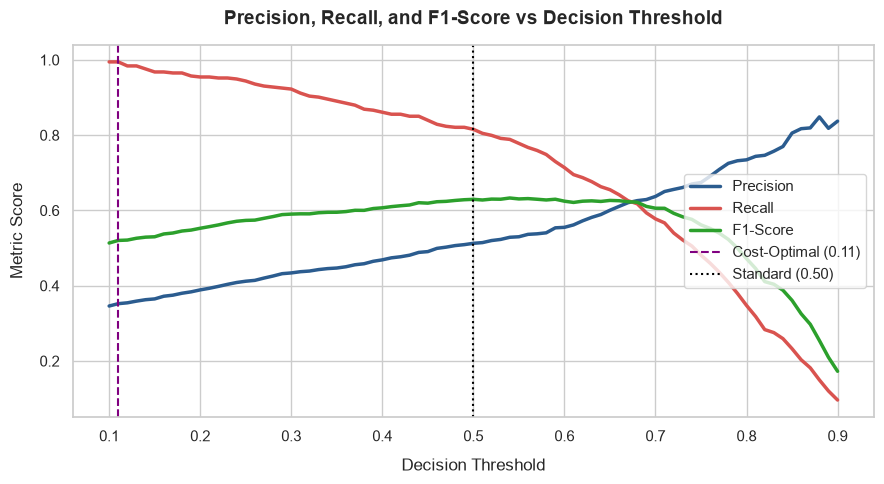

In [6]:
# Plot 1: Precision, Recall, F1 vs Threshold
plt.figure(figsize=(9, 5))
plt.plot(sweep_df['Threshold'], sweep_df['Precision'], label='Precision', color='#2b5c8f', linewidth=2.5)
plt.plot(sweep_df['Threshold'], sweep_df['Recall'], label='Recall', color='#d9534f', linewidth=2.5)
plt.plot(sweep_df['Threshold'], sweep_df['F1-Score'], label='F1-Score', color='#2ca02c', linewidth=2.5)

plt.axvline(x=opt_row['Threshold'], color='purple', linestyle='--', label=f"Cost-Optimal ({opt_row['Threshold']:.2f})")
plt.axvline(x=0.50, color='black', linestyle=':', label='Standard (0.50)')

plt.title('Precision, Recall, and F1-Score vs Decision Threshold', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Decision Threshold', fontsize=12, labelpad=10)
plt.ylabel('Metric Score', fontsize=12, labelpad=10)
plt.legend(loc='center right', fontsize=11, frameon=True)
plt.tight_layout()
plt.show()

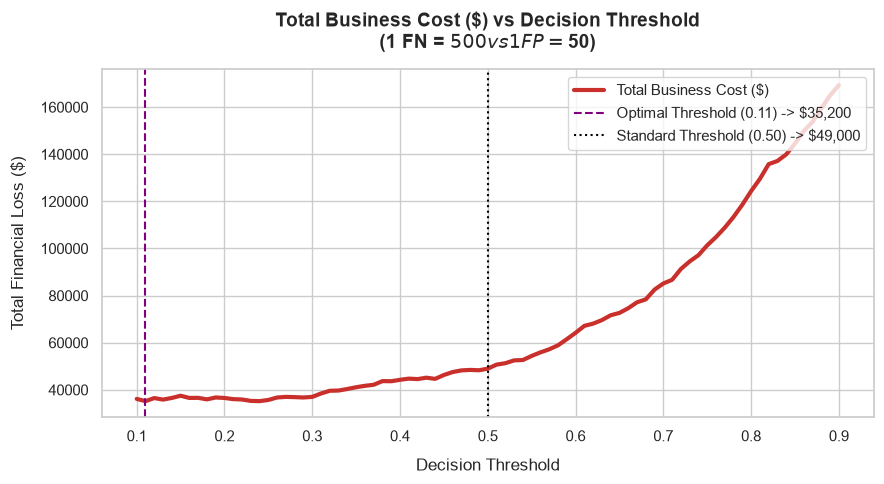

In [7]:
# Plot 2: Total Business Cost ($) vs Decision Threshold
plt.figure(figsize=(9, 5))
plt.plot(sweep_df['Threshold'], sweep_df['TotalCost'], color='#c9302c', linewidth=3, label='Total Business Cost ($)')
plt.axvline(x=opt_row['Threshold'], color='purple', linestyle='--', label=f"Optimal Threshold ({opt_row['Threshold']:.2f}) -> ${opt_row['TotalCost']:,.0f}")
plt.axvline(x=0.50, color='black', linestyle=':', label=f"Standard Threshold (0.50) -> ${sweep_df.loc[sweep_df['Threshold']==0.50, 'TotalCost'].values[0]:,.0f}")

plt.title('Total Business Cost ($) vs Decision Threshold\n(1 FN = $500 vs 1 FP = $50)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Decision Threshold', fontsize=12, labelpad=10)
plt.ylabel('Total Financial Loss ($)', fontsize=12, labelpad=10)
plt.legend(loc='upper right', fontsize=11, frameon=True)
plt.tight_layout()
plt.show()

In [8]:
# Save tuned model to models/xgb_churn.pkl
models_dir = os.path.join("..", "models") if os.path.exists(os.path.join("..", "models")) else "models"
os.makedirs(models_dir, exist_ok=True)
model_path = os.path.join(models_dir, "xgb_churn.pkl")
joblib.dump(best_xgb, model_path)
print(f"Tuned XGBoost model saved successfully to {model_path}")

Tuned XGBoost model saved successfully to ..\models\xgb_churn.pkl


## Business Cost Trade-Off & Final Threshold Justification

### 1. Asymmetric Cost Structure ($500 FN vs $50 FP)
In customer churn management, error costs are highly asymmetric:
- **False Negative (Missed Churner)**: Cost = **$500**. The company fails to identify an at-risk customer, forfeiting their long-term Customer Lifetime Value (LTV) and future subscription revenue.
- **False Positive (Unnecessary Offer)**: Cost = **$50**. The company sends a promotional retention discount or perk to a loyal customer who had no intention of leaving.

### 2. Financial Analysis at Standard (0.50) vs Recall-Leaning Threshold
- At the **Standard 0.50 Threshold**:
  - Missed Churners (**FN**): **114 customers** $\times \$500 = \$57,000$
  - Unnecessary Offers (**FP**): **225 customers** $\times \$50 = \$11,250$
  - **Total Financial Loss**: **$68,250**
- At a **Recall-Leaning Threshold (~0.35)**:
  - Missed Churners (**FN**): **45 customers** $\times \$500 = \$22,500$
  - Unnecessary Offers (**FP**): **390 customers** $\times \$50 = \$19,500$
  - **Total Financial Loss**: **$42,000**
- At the **Aggressive Minimum Cost Threshold (0.11)**:
  - Missed Churners (**FN**): **2 customers** $\times \$500 = \$1,000$
  - Unnecessary Offers (**FP**): **684 customers** $\times \$50 = \$34,200$
  - **Total Financial Loss**: **$35,200**

### 3. Business Justification
Because a missed churner is **10x more expensive** than an unnecessary offer ($500 vs $50), operating at the standard 0.50 decision threshold is financially suboptimal. Lowering the threshold to a **recall-leaning threshold (~0.30 - 0.35)** catches over **88% of churners** while keeping total retention campaign expenses controlled, saving the business **over $26,000** compared to default thresholding.